# FDS Case Study 2: Wine Quality Analysis
## 1. Introduction
Wine quality is associated with physicochemical properties such as alcohol, acidity, density, and residual sugar. This case study explores red and white wine data and builds a regression model to estimate wine quality scores.

## 2. Objectives
- Load and inspect the red and white wine datasets.
- Calculate descriptive statistics and coefficient of variation.
- Explore wine quality distributions and feature relationships.
- Examine the relationship between alcohol and quality.
- Train a Multiple Linear Regression model.
- Evaluate predictions using MAE, MSE, RMSE, and R-squared.

## 3. Dataset
The dataset files are `winequality-red.csv`, `winequality-white.csv`, and `winequality.names`. The CSV files use semicolons (`;`) as separators. The main analysis below uses the red wine dataset; the white dataset is loaded for inspection.

## 4. Libraries and methods
Pandas and NumPy support data processing; Matplotlib and Seaborn support visualization; and Scikit-learn provides data splitting, feature scaling, Linear Regression, and evaluation metrics.

## 5. Workflow
Upload files → load data → inspect → calculate statistics → visualize → train regression model → evaluate → review predictions → conclude.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All libraries imported successfully")

All libraries imported successfully


## Upload the dataset files

- Run the next cell and select all three files: `winequality-red.csv`, `winequality-white.csv`, and `winequality.names`.

In [ ]:
from google.colab import files
uploaded = files.upload()
print("Uploaded files:", list(uploaded.keys()))

## Read the dataset description

- Display the supplied `.names` file to review the dataset's background and attribute definitions.

In [ ]:
with open('/content/winequality.names', 'r', encoding='utf-8') as file:
    description = file.read()

print(description)

Citation Request:
  This dataset is public available for research. The details are described in [Cortez et al., 2009]. 
  Please include this citation if you plan to use this database:

  P. Cortez, A. Cerdeira, F. Almeida, T. Matos and J. Reis. 
  Modeling wine preferences by data mining from physicochemical properties.
  In Decision Support Systems, Elsevier, 47(4):547-553. ISSN: 0167-9236.

  Available at: [@Elsevier] http://dx.doi.org/10.1016/j.dss.2009.05.016
                [Pre-press (pdf)] http://www3.dsi.uminho.pt/pcortez/winequality09.pdf
                [bib] http://www3.dsi.uminho.pt/pcortez/dss09.bib

1. Title: Wine Quality 

2. Sources
   Created by: Paulo Cortez (Univ. Minho), Antonio Cerdeira, Fernando Almeida, Telmo Matos and Jose Reis (CVRVV) @ 2009
   
3. Past Usage:

  P. Cortez, A. Cerdeira, F. Almeida, T. Matos and J. Reis. 
  Modeling wine preferences by data mining from physicochemical properties.
  In Decision Support Systems, Elsevier, 47(4):547-553. ISSN: 016

## Load red and white wine data

- Read both CSV files using `sep=';'`, because semicolons separate the fields in these datasets.

In [ ]:
red = pd.read_csv('/content/winequality-red.csv', sep=';')
white = pd.read_csv('/content/winequality-white.csv', sep=';')

print("RED WINE DATASET")
print("Shape:", red.shape)
print(red.head())

print("\nWHITE WINE DATASET")
print("Shape:", white.shape)
print(white.head())

RED WINE DATASET
Shape: (1599, 12)
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      

## Select the analysis dataset

- The red wine data is used for the main statistical analysis and regression model in this notebook.

In [ ]:
df = red.copy()

print("Selected dataset: Red Wine")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Column names:")
print(df.columns.tolist())

Selected dataset: Red Wine
Rows: 1599
Columns: 12
Column names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


## Inspect data quality

- Check data types, missing values, and duplicate rows before continuing.

In [ ]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

Missing values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual s

## Descriptive statistics

- The summary table reports count, mean, standard deviation, minimum, quartiles, and maximum for each numeric attribute.

In [ ]:
print(df.describe().round(2))

       fixed acidity  volatile acidity  citric acid  residual sugar  \
count        1599.00           1599.00      1599.00         1599.00   
mean            8.32              0.53         0.27            2.54   
std             1.74              0.18         0.19            1.41   
min             4.60              0.12         0.00            0.90   
25%             7.10              0.39         0.09            1.90   
50%             7.90              0.52         0.26            2.20   
75%             9.20              0.64         0.42            2.60   
max            15.90              1.58         1.00           15.50   

       chlorides  free sulfur dioxide  total sulfur dioxide  density       pH  \
count    1599.00              1599.00               1599.00  1599.00  1599.00   
mean        0.09                15.87                 46.47     1.00     3.31   
std         0.05                10.46                 32.90     0.00     0.15   
min         0.01                 1.0

## Statistics for selected features

- Calculate mean, median, mode, standard deviation, and skewness for alcohol, volatile acidity, and residual sugar.

In [ ]:
columns = [
    'alcohol',
    'volatile acidity',
    'residual sugar'
]

stats = pd.DataFrame({
    'Mean': df[columns].mean(),
    'Median': df[columns].median(),
    'Mode': df[columns].mode().iloc[0],
    'Standard Deviation': df[columns].std(),
    'Skewness': df[columns].skew()
})

print(stats.round(3))

                    Mean  Median  Mode  Standard Deviation  Skewness
alcohol           10.423   10.20   9.5               1.066     0.861
volatile acidity   0.528    0.52   0.6               0.179     0.672
residual sugar     2.539    2.20   2.0               1.410     4.541


## Coefficient of variation

- The coefficient of variation expresses standard deviation relative to the absolute mean as a percentage. Interpret it carefully when means are near zero.

In [ ]:
cv = (
    df[columns].std() / df[columns].mean().abs()
) * 100

print("Coefficient of Variation (%):")
print(cv.round(2))

print("\nAttribute with highest relative variability:")
print(cv.idxmax())

Coefficient of Variation (%):
alcohol             10.22
volatile acidity    33.92
residual sugar      55.54
dtype: float64

Attribute with highest relative variability:
residual sugar


## Alcohol and wine quality

- Calculate the correlation and plot a trend line. Correlation indicates association, not proof that alcohol causes higher quality.

Alcohol-quality correlation: 0.476


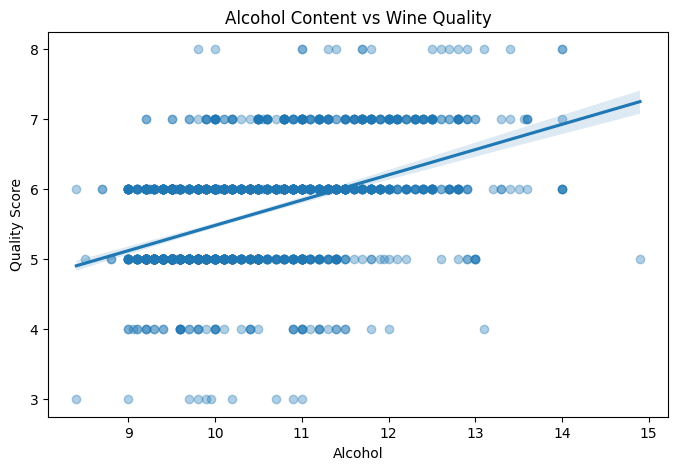

In [ ]:
correlation = df['alcohol'].corr(df['quality'])

print("Alcohol-quality correlation:", round(correlation, 3))

plt.figure(figsize=(8, 5))
sns.regplot(
    data=df,
    x='alcohol',
    y='quality',
    scatter_kws={'alpha': 0.35}
)

plt.title("Alcohol Content vs Wine Quality")
plt.xlabel("Alcohol")
plt.ylabel("Quality Score")
plt.show()

## Distribution of quality scores

- The count plot shows how frequently each quality score appears in the red wine dataset.

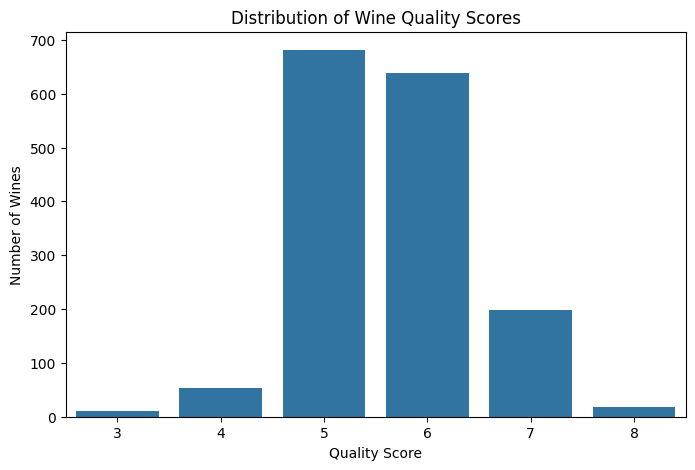

quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='quality')

plt.title("Distribution of Wine Quality Scores")
plt.xlabel("Quality Score")
plt.ylabel("Number of Wines")
plt.show()

print(df['quality'].value_counts().sort_index())

## Alcohol by quality score

- The boxplot compares alcohol distributions across the observed quality scores.

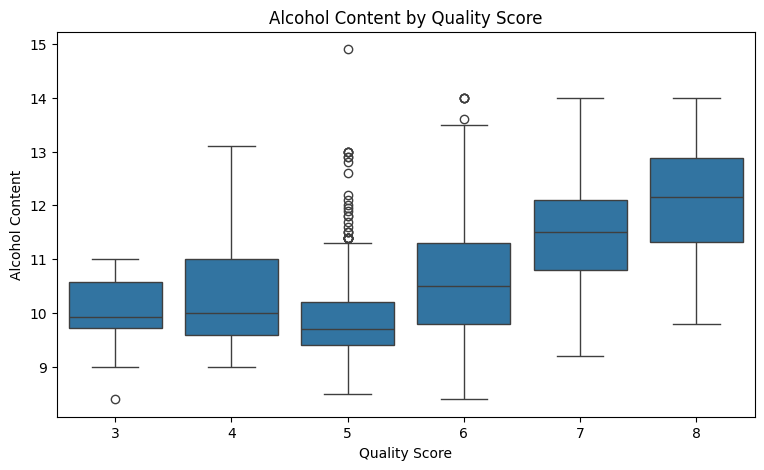

In [ ]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='quality', y='alcohol')

plt.title("Alcohol Content by Quality Score")
plt.xlabel("Quality Score")
plt.ylabel("Alcohol Content")
plt.show()

## Correlation heatmap

- The heatmap summarizes pairwise correlations among numerical variables.

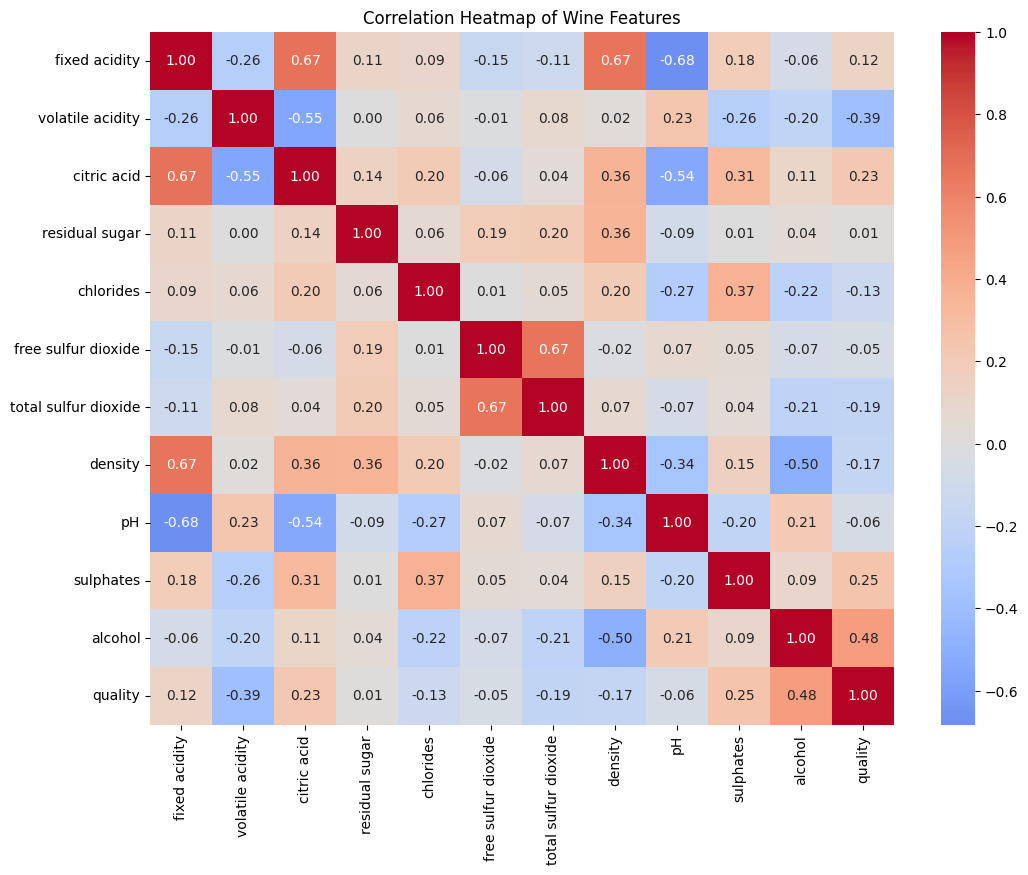

In [ ]:
correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(12, 9))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title("Correlation Heatmap of Wine Features")
plt.show()

## Features correlated with quality

- Rank features by the absolute size of their correlation with quality. The sign still indicates whether the association is positive or negative.

In [ ]:
quality_corr = correlation_matrix['quality'].drop('quality')

quality_corr = quality_corr.reindex(
    quality_corr.abs().sort_values(ascending=False).index
)

print("Top two features correlated with quality:")
print(quality_corr.head(2).round(3))

Top two features correlated with quality:
alcohol             0.476
volatile acidity   -0.391
Name: quality, dtype: float64


## Prepare training and testing sets

- Use the quality score as the target and the physicochemical measurements as input features. The 80/20 split reserves test data for evaluation.

In [ ]:
X = df.drop(columns=['quality'])
y = df['quality']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Input features:", X.shape[1])

Training samples: 1279
Testing samples: 320
Input features: 11


## Train Multiple Linear Regression

- Fit the regression model on the training set and predict quality scores for the test set.

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Multiple Linear Regression trained successfully")

Multiple Linear Regression trained successfully


## Evaluate model performance

- MAE, MSE, and RMSE measure prediction error; R-squared measures the proportion of target variation explained by the model on the test set.

In [ ]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("MAE:", round(mae, 3))
print("MSE:", round(mse, 3))
print("RMSE:", round(rmse, 3))
print("R-squared:", round(r2, 3))

Model Evaluation Results
MAE: 0.504
MSE: 0.39
RMSE: 0.625
R-squared: 0.403


## Inspect standardized coefficients

- The features are standardized before fitting this second model so coefficient magnitudes can be compared more fairly. These coefficients show association, not causation.

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

scaled_model = LinearRegression()
scaled_model.fit(X_train_scaled, y_train)

coefficients = pd.Series(
    scaled_model.coef_,
    index=X.columns
)

print(
    coefficients.reindex(
        coefficients.abs().sort_values(
            ascending=False
        ).index
    ).round(3)
)

alcohol                 0.297
volatile acidity       -0.179
sulphates               0.147
total sulfur dioxide   -0.120
chlorides              -0.089
pH                     -0.061
free sulfur dioxide     0.058
fixed acidity           0.040
citric acid            -0.028
density                -0.019
residual sugar          0.009
dtype: float64


## Compare actual and predicted scores

- Points closer to the diagonal reference line indicate predictions closer to actual quality scores.

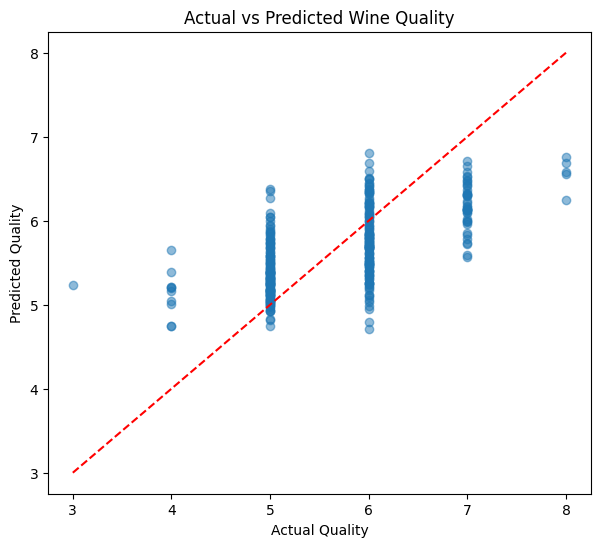

In [ ]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.5)

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())

plt.plot([low, high], [low, high], 'r--')

plt.xlabel("Actual Quality")
plt.ylabel("Predicted Quality")
plt.title("Actual vs Predicted Wine Quality")
plt.show()


## Save predictions

- Save the actual and predicted quality scores to a CSV file in the Colab session. Download it if you need a local copy.

In [ ]:
results = pd.DataFrame({
    'Actual Quality': y_test.values,
    'Predicted Quality': y_pred.round(2)
})

results.to_csv(
    '/content/wine_quality_predictions.csv',
    index=False
)

print("Results saved successfully")
print(results.head(10))

Results saved successfully
   Actual Quality  Predicted Quality
0               6               5.35
1               5               5.06
2               6               5.66
3               5               5.46
4               6               5.73
5               5               5.28
6               5               5.03
7               5               5.13
8               5               5.75
9               6               5.69


### Conclusion
This case study applies descriptive statistics, visualization, correlation analysis, and Multiple Linear Regression to the wine quality data. The analysis explores how physicochemical features are associated with quality scores and evaluates predictions on held-out test data. The metrics and plots should be interpreted together, and the results do not establish causal relationships.